# 05 · Results

Evaluation uses only data the models never trained on:
* **Gold:** the 58 radiologist-labelled studies, the validation set of every fold (scored with last-epoch weights, no TTA).
* **Kaggle leaderboard:** about 1,300 hidden test studies (public and private splits).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kneemri.constants import LABELS
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MET = ROOT / "reports" / "metrics"; MET.mkdir(parents=True, exist_ok=True)

In [2]:
import glob, os, re
from kneemri.metrics import per_finding_auc
from kneemri.inference import rank_ensemble, family_of

train = pd.read_csv(ROOT / "data" / "train.csv")
gold = train[train[LABELS].notna().all(axis=1)].set_index("StudyInstanceUID")[LABELS]
RUNS = sorted(glob.glob(str(ROOT / "outputs" / "runs" / "*_f*")))
FAMILY_NAMES = {"cnxt_fov140": "ConvNeXt-T · 140 mm", "cnxt_zoom110": "ConvNeXt-T · 110 mm zoom",
                "cnxt_native_mirror": "ConvNeXt-T · native FOV + mirror"}
preds = {r: pd.read_csv(f"{r}/gold_predictions.csv").set_index("StudyInstanceUID").loc[gold.index, LABELS].values for r in RUNS}
print(len(RUNS), "models:", sorted({family_of(r) for r in RUNS}))

15 models: ['cnxt_fov140', 'cnxt_native_mirror', 'cnxt_zoom110']


## Training curves (gold macro AUC per epoch)

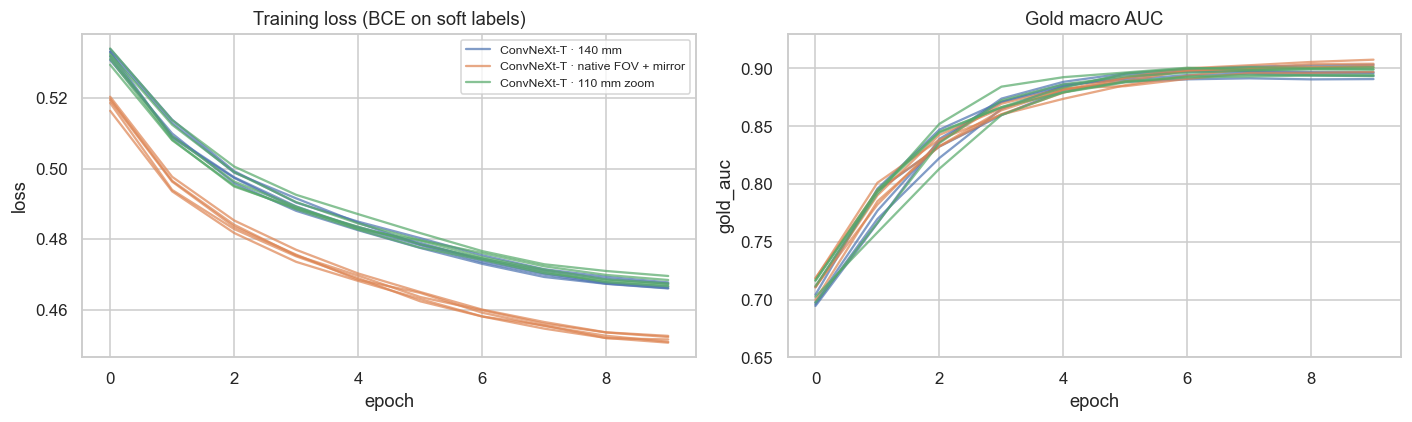

In [3]:
hist = pd.concat([pd.read_csv(f"{r}/history.csv").assign(run=os.path.basename(r), family=FAMILY_NAMES[family_of(r)]) for r in RUNS])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=hist, x="epoch", y="loss", hue="family", units="run", estimator=None, alpha=0.7, ax=ax[0])
sns.lineplot(data=hist, x="epoch", y="gold_auc", hue="family", units="run", estimator=None, alpha=0.7, ax=ax[1], legend=False)
ax[0].set(title="Training loss (BCE on soft labels)"); ax[1].set(title="Gold macro AUC", ylim=(0.65, 0.93))
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "05_training_curves.png"); plt.show()

## Single models → family ensembles → final ensemble

In [4]:
rows = [dict(model=os.path.basename(r), family=FAMILY_NAMES[family_of(r)], macro_auc=np.mean(list(per_finding_auc(gold.values, p).values())))
        for r, p in preds.items()]
for fam in FAMILY_NAMES:
    sub = {r: p for r, p in preds.items() if family_of(r) == fam}
    rows.append(dict(model=f"{fam} (5-fold ensemble)", family=FAMILY_NAMES[fam],
                     macro_auc=np.mean(list(per_finding_auc(gold.values, rank_ensemble(sub)).values()))))
final = rank_ensemble(preds)
final_auc = per_finding_auc(gold.values, final)
rows.append(dict(model="FINAL: 15 models, family-equal rank average", family="ensemble", macro_auc=np.mean(list(final_auc.values()))))
summary = pd.DataFrame(rows); summary.round(4).to_csv(MET / "gold_auc_by_model.csv", index=False)
summary.round(4)

,model,family,macro_auc
0,cnxt_fov140_f0,ConvNeXt-T · 140 mm,0.8967
1,cnxt_fov140_f1,ConvNeXt-T · 140 mm,0.9032
2,cnxt_fov140_f2,ConvNeXt-T · 140 mm,0.8936
3,cnxt_fov140_f3,ConvNeXt-T · 140 mm,0.8908
4,cnxt_fov140_f4,ConvNeXt-T · 140 mm,0.8958
5,cnxt_native_mirror_f0,ConvNeXt-T · native FOV + mirror,0.9076
6,cnxt_native_mirror_f1,ConvNeXt-T · native FOV + mirror,0.9040
7,cnxt_native_mirror_f2,ConvNeXt-T · native FOV + mirror,0.9024
8,cnxt_native_mirror_f3,ConvNeXt-T · native FOV + mirror,0.9010
9,cnxt_native_mirror_f4,ConvNeXt-T · native FOV + mirror,0.8969


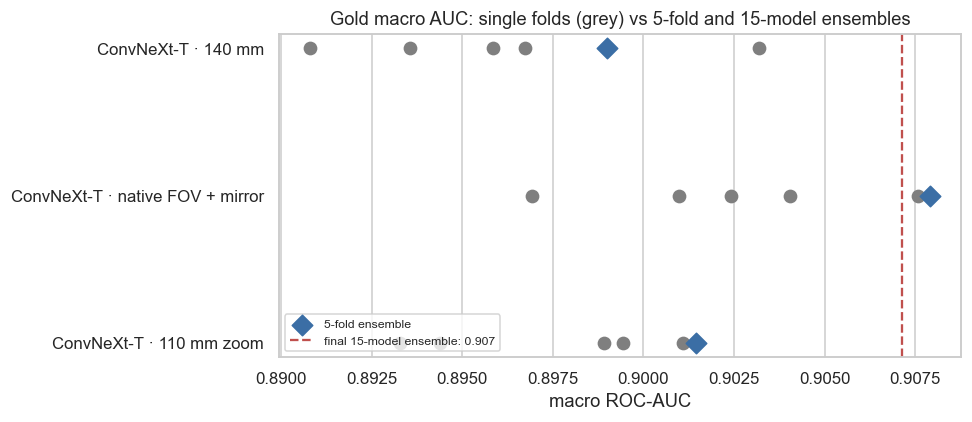

In [5]:
single = summary[~summary.model.str.contains("ensemble|FINAL")]
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(data=single, x="macro_auc", y="family", size=9, ax=ax, color="#7f7f7f", jitter=False)
fam_rows = summary[summary.model.str.contains("5-fold")]
ax.scatter(fam_rows.macro_auc, fam_rows.family, marker="D", s=90, color="#3b6ea5", label="5-fold ensemble", zorder=3)
ax.axvline(summary.macro_auc.iloc[-1], color="#c0504d", ls="--", label=f"final 15-model ensemble: {summary.macro_auc.iloc[-1]:.3f}")
ax.set(title="Gold macro AUC: single folds (grey) vs 5-fold and 15-model ensembles", xlabel="macro ROC-AUC", ylabel="")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.savefig(FIG / "05_ensemble_gain.png"); plt.show()

## Per-finding performance of the final ensemble

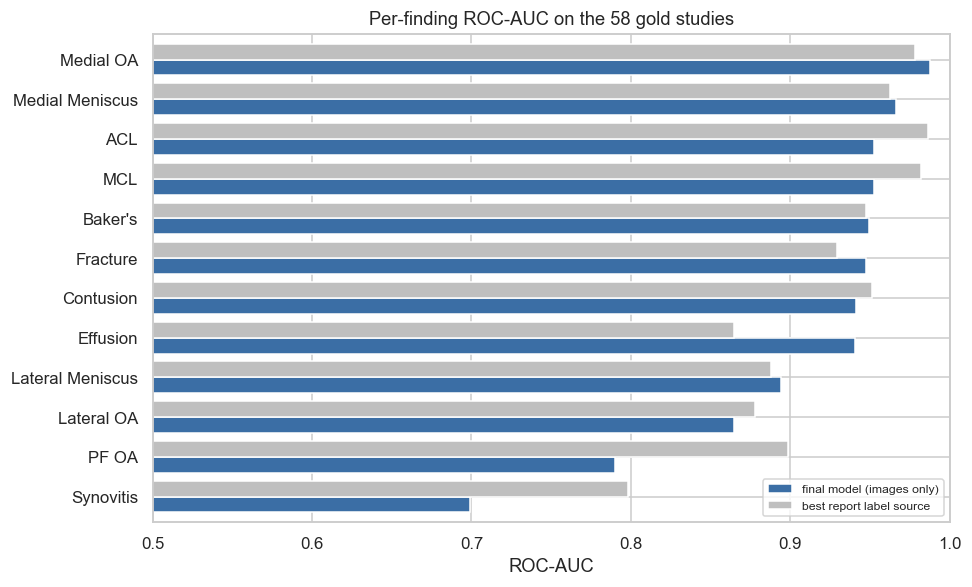

,final model (images only),best report label source
Synovitis,0.699,0.798
PF OA,0.790,0.898
Lateral OA,0.865,0.878
Lateral Meniscus,0.894,0.888
Effusion,0.940,0.865
Contusion,0.941,0.951
Fracture,0.947,0.929
Baker's,0.949,0.948
MCL,0.952,0.982
ACL,0.953,0.986


In [6]:
label_q = pd.read_csv(MET / "label_quality_vs_gold.csv", index_col=0)
per = pd.DataFrame({"final model (images only)": pd.Series(final_auc),
                    "best report label source": label_q.drop(index="macro").drop(columns="Blend").max(axis=1)})
per = per.sort_values("final model (images only)")
ax = per.plot.barh(figsize=(9, 5.5), color=["#3b6ea5", "#bfbfbf"], width=0.8)
ax.set(xlim=(0.5, 1.0), title="Per-finding ROC-AUC on the 58 gold studies", xlabel="ROC-AUC")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "05_per_finding_auc.png"); plt.show()
per.round(3).to_csv(MET / "final_per_finding_auc.csv"); per.round(3)

## Kaggle leaderboard
RSNA Knee Abnormality Detection (research code competition, 6,425 teams). Final submission: the 15-model ensemble above.

In [7]:
lb = pd.DataFrame([dict(submission="15 ConvNeXt-T models (3 families × 5 folds), family-equal rank average, TTA",
                        public_auc=0.920, private_auc=0.906, gold_auc=round(summary.macro_auc.iloc[-1], 3))])
lb.to_csv(MET / "leaderboard.csv", index=False); lb

,submission,public_auc,private_auc,gold_auc
0,"15 ConvNeXt-T models (3 families × 5 folds), f...",0.92,0.906,0.907


**Takeaways**
* The image-only ensemble scores **0.907 macro AUC on gold** and **0.906 on the private leaderboard**: gold tracks the hidden test set closely.
* On gold, the 3-family ensemble (0.907) matches the best single family (native FOV + mirror, 0.908): the difference is within
  gold noise. Every 5-fold ensemble beats its own average fold, and mixing three preprocessing views was kept for robustness on the hidden test set.
* The image-only model beats the best report-derived label source for effusion, fracture, medial OA and lateral meniscus,
  and trails it on synovitis and PF OA, the findings where reports and images disagree most. Label quality is the ceiling, not model capacity.